# CS 6220 Data Mining Homework 02
**Name:** Rutuja Jadhav



## Part 1: Data Generator

In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split


def generate_noisy_dataset(functions, true_function, x_range, n_samples, noise_level, random_state=None):
    rng = np.random.default_rng(random_state)

    low, high = x_range
    x = rng.uniform(low, high, size=n_samples)

    data = {'x': x}
    for i, f in enumerate(functions, start=1):
        data[f'f_{i}'] = f(x)

    noise = rng.uniform(-noise_level, noise_level, size=n_samples)
    y = true_function(x) + noise
    data['y'] = y

    df = pd.DataFrame(data)
    return df


def split_dataset(df, test_size=0.2, random_state=42):
    train_df, test_df = train_test_split(df, test_size=test_size, random_state=random_state)
    return train_df, test_df

### run function to generate data & split into train and test


In [8]:
df = generate_noisy_dataset(
    functions=[lambda x: x**2, lambda x: x**3],
    true_function=lambda x: np.log(x),
    x_range=(0.0, 1.0),
    n_samples=1000,
    noise_level=0.1,
    random_state=42
)

train_df, test_df = split_dataset(df, test_size=0.2, random_state=42)

print(df)
print("Shape of training Data: ",train_df.shape)
print("Shape of testing Data: ",test_df.shape)


            x       f_1           f_2         y
0    0.773956  0.599008  4.636058e-01 -0.343828
1    0.438878  0.192614  8.453426e-02 -0.831880
2    0.858598  0.737190  6.329501e-01 -0.226649
3    0.697368  0.486322  3.391455e-01 -0.429977
4    0.094177  0.008869  8.352940e-04 -2.336119
..        ...       ...           ...       ...
995  0.437990  0.191835  8.402169e-02 -0.774806
996  0.639014  0.408338  2.609338e-01 -0.490805
997  0.002309  0.000005  1.230675e-08 -6.104030
998  0.993368  0.986781  9.802371e-01  0.062486
999  0.280896  0.078903  2.216351e-02 -1.265755

[1000 rows x 4 columns]
Shape of training Data:  (800, 4)
Shape of testing Data:  (200, 4)


## Part 2: Linear Regression

### train data (calculate 𝜷)

In [15]:
def fit(train_dataset):
    # get the input columns (everything except y)
    input_cols = [c for c in train_dataset.columns if c != 'y']
    X_raw = train_dataset[input_cols].values  # shape (n, d)

    # make a vector of 1s
    ones = np.ones((X_raw.shape[0], 1))

    # define the X and Y vectors
    X = np.hstack([ones, X_raw])  # shape (n, d+1), intercept column first
    Y = train_dataset['y'].values  # shape (n,)

    # 𝜷 = (𝑿𝑇𝑿)−1 𝑿𝑇𝒀
      # .T -> transpose
      # @ -> multiplies vector
      # np.linalg.inv() -> inverse
    beta_value = np.linalg.inv(X.T @ X)@X.T@Y

    return beta_value


beta = fit(train_df)
print("beta:", beta)

beta: [ -3.86058992  14.80895591 -22.34245243  11.66759006]


### test data (prediction)


In [16]:
def predict(test_dataset, beta):
    # get the input columns (everything except y)
    input_cols = [c for c in test_dataset.columns if c != 'y']
    X_raw = test_dataset[input_cols].values  # shape (n, d)

    # make a vector of 1s
    ones = np.ones((X_raw.shape[0], 1))

    # define the X vector
    X = np.hstack([ones, X_raw])  # shape (n, d+1), intercept column first

    # pred = X.𝜷
    prediction = X@beta

    return prediction

y_pred = predict(test_df, beta)
print(y_pred[:10])  # first 10 predictions

[-0.84207024 -1.10431628 -3.83605814 -1.23603007 -0.47017374 -2.24583263
 -0.34780745 -1.20652579 -0.56390502  0.08195581]


### evaluate (RMSE)

In [17]:
def evaluate_model(prediction, y_true):
  errors = prediction - y_true        # elementwise subtraction
  squared_errors = errors ** 2        # elementwise square
  mse = np.mean(squared_errors)       # mean squared error
  rmse = np.sqrt(mse)                 # root mean square error
  return rmse

rmse_error = evaluate_model(y_pred, test_df['y'].values)
print("RMSE:", rmse_error)

RMSE: 0.27327355733052033


## Part 2: Regression Tree

In [20]:
import matplotlib.pyplot as plt

class RegressionTree:

    def fit(self, dataset, min_records):
        self.min_records = min_records
        self.x_min = dataset['x'].min()
        self.x_max = dataset['x'].max()
        self.root = self.tree_build(dataset)

    def compute_sse(self, y_values):
        mean_y = y_values.mean()
        return ((y_values - mean_y) ** 2).sum()

    def tree_build(self, data):
        input_cols = [c for c in data.columns if c != 'y']

        if len(data) < self.min_records:
            return {'leaf': True, 'value': np.mean(data['y'].values)}

        best_sse = None
        best_feature = None
        best_threshold = None

        for feature in input_cols:
            values = sorted(data[feature].unique())
            for i in range(len(values) - 1):
                threshold = (values[i] + values[i + 1]) / 2
                left = data[data[feature] <= threshold]
                right = data[data[feature] > threshold]
                if len(left) == 0 or len(right) == 0:
                    continue

                current_sse = self.compute_sse(left['y']) + self.compute_sse(right['y'])

                if best_sse is None or current_sse < best_sse:
                    best_sse = current_sse
                    best_feature = feature
                    best_threshold = threshold

        if best_feature is None:
            return {'leaf': True, 'value': data['y'].mean()}

        left_data = data[data[best_feature] <= best_threshold]
        right_data = data[data[best_feature] > best_threshold]

        return {
            'leaf': False,
            'feature': best_feature,
            'threshold': best_threshold,
            'left': self.tree_build(left_data),
            'right': self.tree_build(right_data)
        }

    def predict(self, X):
        predictions = []
        for _, row in X.iterrows():
            predictions.append(self._predict_one(row, self.root))
        return np.array(predictions)

    def _predict_one(self, row, node):
        if node['leaf']:
            return node['value']
        if row[node['feature']] <= node['threshold']:
            return self._predict_one(row, node['left'])
        else:
            return self._predict_one(row, node['right'])

    def visualize(self, functions=None):
        x_vals = np.linspace(self.x_min, self.x_max, 500)
        X_plot = pd.DataFrame({'x': x_vals})

        if functions is not None:
            for i, f in enumerate(functions, start=1):
                X_plot[f'f_{i}'] = f(x_vals)

        y_vals = self.predict(X_plot)

        plt.plot(x_vals, y_vals, label='Tree prediction')
        plt.xlabel('x')
        plt.ylabel('predicted y')
        plt.legend()
        plt.show()

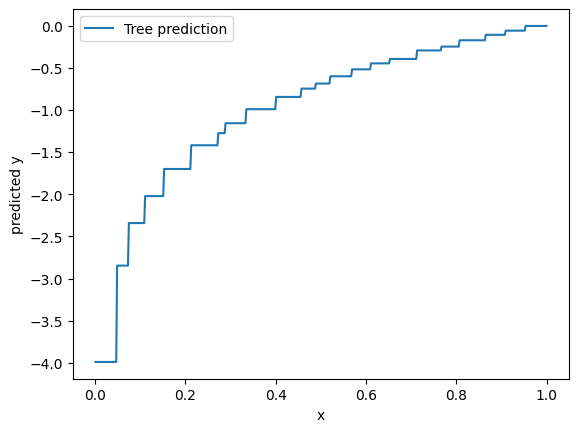

In [22]:
# 1. create a tree and fit it
tree = RegressionTree()
tree.fit(train_df, min_records=50)   # use your actual train_df and a chosen min_records

# 2. now you can predict
preds = tree.predict(test_df[['x']])   # or whatever input columns your schema uses

# 3. now you can visualize
tree.visualize(functions=[lambda x: x**2, lambda x: x**3])

## Report — Experiments

### Question 3

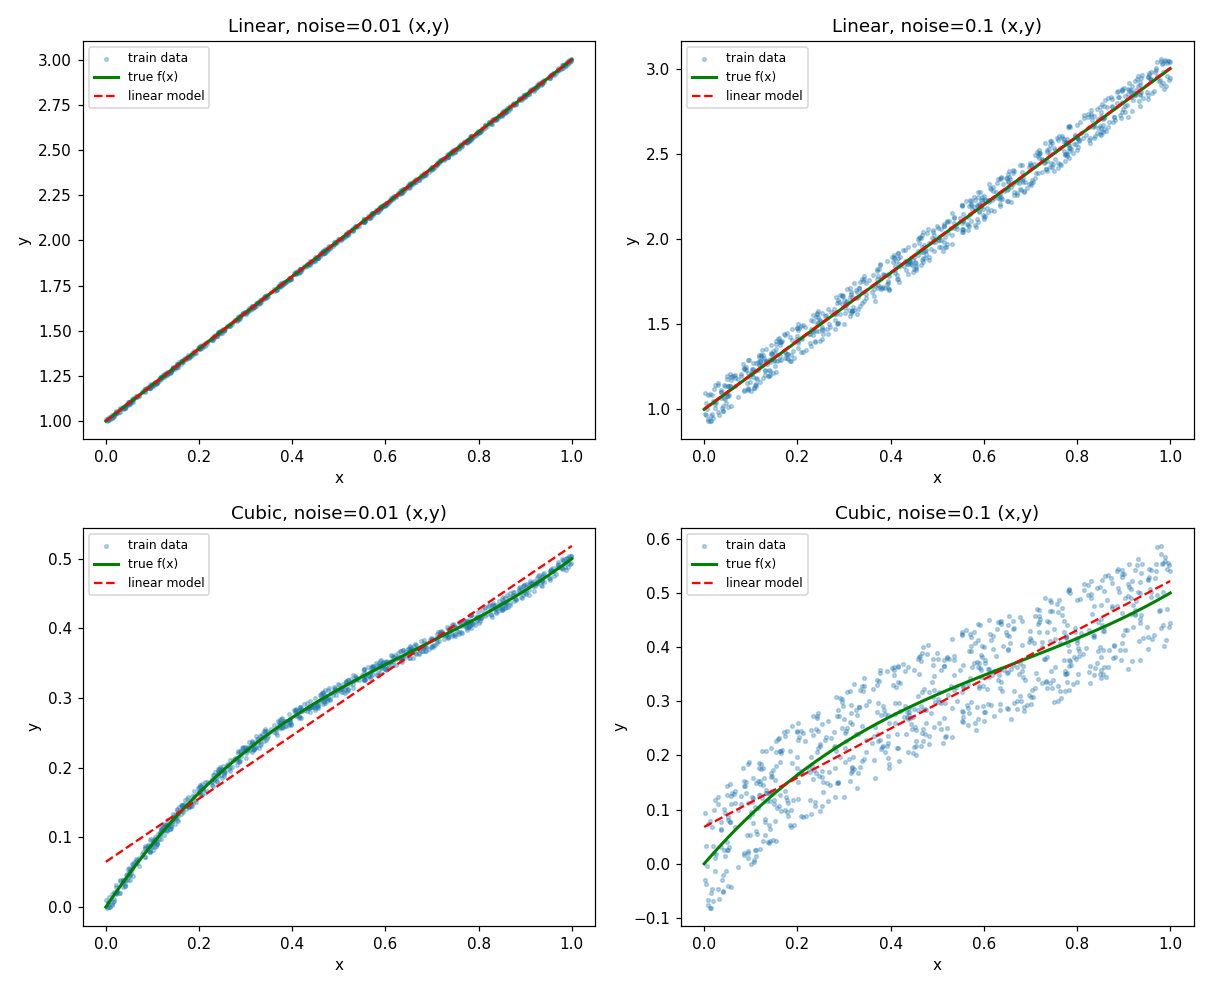

('Linear', 0.01, 'xy') -> beta: [1.0003 2.0001]  rmse_train: 0.0059  rmse_test: 0.0054
('Linear', 0.1, 'xy') -> beta: [1.0034 2.0009]  rmse_train: 0.0588  rmse_test: 0.0542
('Cubic', 0.01, 'xy') -> beta: [0.065  0.4533]  rmse_train: 0.0217  rmse_test: 0.0215
('Cubic', 0.1, 'xy') -> beta: [0.068  0.4541]  rmse_train: 0.0623  rmse_test: 0.0594


In [ ]:
true_functions = {
    'Linear': lambda x: 2*x + 1,
    'Cubic': lambda x: 0.5*x**3 - x**2 + x
}
noise_levels = [0.01, 0.1]
n_samples = 1000
x_range = (0.0, 1.0)
extra_functions = [lambda x: x**2, lambda x: x**3]

x_grid = np.linspace(x_range[0], x_range[1], 300)
results = {}

fig3, axes3 = plt.subplots(2, 2, figsize=(11, 9))
idx = 0
for func_name, true_f in true_functions.items():
    for noise in noise_levels:
        df_full = generate_noisy_dataset(
            functions=extra_functions, true_function=true_f, x_range=x_range,
            n_samples=n_samples, noise_level=noise, random_state=42
        )
        train_full, test_full = split_dataset(df_full, test_size=0.2, random_state=42)

        train_xy = train_full[['x', 'y']]
        test_xy = test_full[['x', 'y']]

        beta_xy = fit(train_xy)
        pred_train_xy = predict(train_xy, beta_xy)
        pred_test_xy = predict(test_xy, beta_xy)
        rmse_train_xy = evaluate_model(pred_train_xy, train_xy['y'].values)
        rmse_test_xy = evaluate_model(pred_test_xy, test_xy['y'].values)

        results[(func_name, noise, 'xy')] = {
            'beta': beta_xy, 'rmse_train': rmse_train_xy, 'rmse_test': rmse_test_xy
        }

        ax = axes3.flatten()[idx]
        ax.scatter(train_xy['x'], train_xy['y'], s=6, alpha=0.3, label='train data')
        ax.plot(x_grid, true_f(x_grid), color='green', label='true f(x)', linewidth=2)
        model_grid_xy = pd.DataFrame({'x': x_grid})
        ax.plot(x_grid, predict(model_grid_xy, beta_xy), color='red', linestyle='--', label='linear model')
        ax.set_title(f'{func_name}, noise={noise} (x,y)')
        ax.set_xlabel('x'); ax.set_ylabel('y')
        ax.legend(fontsize=8)
        idx += 1

fig3.tight_layout()
plt.show()

for key, val in results.items():
    print(key, '-> beta:', np.round(val['beta'], 4),
          ' rmse_train:', round(val['rmse_train'],4), ' rmse_test:', round(val['rmse_test'],4))

### Question 4

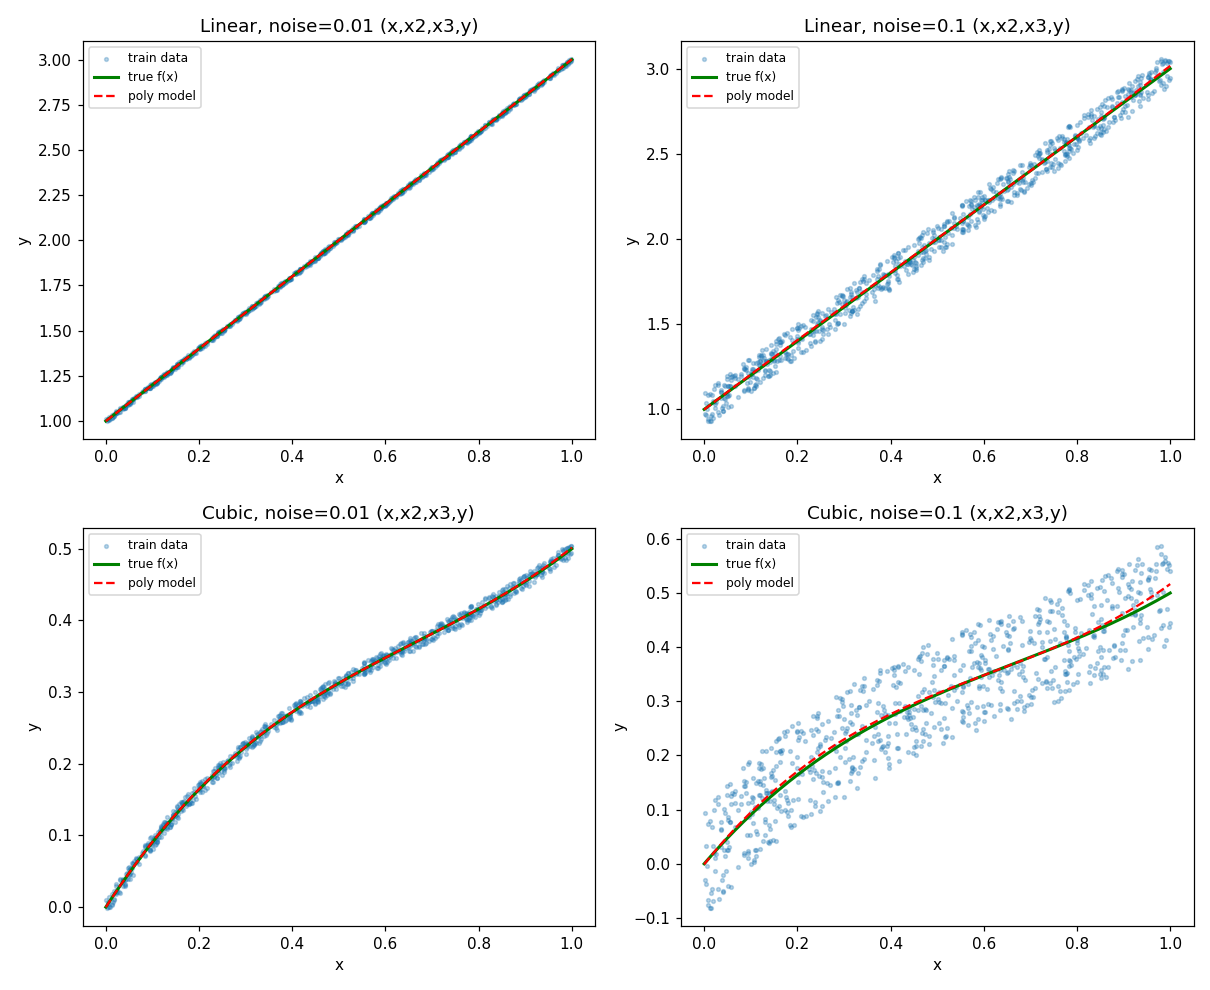

('Linear', 0.01, 'poly') -> beta: [ 0.9999  2.0075 -0.0219  0.0161]  rmse_train: 0.0059  rmse_test: 0.0054
('Linear', 0.1, 'poly') -> beta: [ 0.999   2.0751 -0.2189  0.1613]  rmse_train: 0.0587  rmse_test: 0.0543
('Cubic', 0.01, 'poly') -> beta: [-0.0001  1.0075 -1.0219  0.5161]  rmse_train: 0.0059  rmse_test: 0.0054
('Cubic', 0.1, 'poly') -> beta: [-0.001   1.0751 -1.2189  0.6613]  rmse_train: 0.0587  rmse_test: 0.0543


In [ ]:
fig4, axes4 = plt.subplots(2, 2, figsize=(11, 9))
idx = 0
for func_name, true_f in true_functions.items():
    for noise in noise_levels:
        df_full = generate_noisy_dataset(
            functions=extra_functions, true_function=true_f, x_range=x_range,
            n_samples=n_samples, noise_level=noise, random_state=42
        )
        train_full, test_full = split_dataset(df_full, test_size=0.2, random_state=42)

        train_poly = train_full[['x', 'f_1', 'f_2', 'y']]
        test_poly = test_full[['x', 'f_1', 'f_2', 'y']]

        beta_poly = fit(train_poly)
        pred_train_poly = predict(train_poly, beta_poly)
        pred_test_poly = predict(test_poly, beta_poly)
        rmse_train_poly = evaluate_model(pred_train_poly, train_poly['y'].values)
        rmse_test_poly = evaluate_model(pred_test_poly, test_poly['y'].values)

        results[(func_name, noise, 'poly')] = {
            'beta': beta_poly, 'rmse_train': rmse_train_poly, 'rmse_test': rmse_test_poly
        }

        ax2 = axes4.flatten()[idx]
        ax2.scatter(train_poly['x'], train_poly['y'], s=6, alpha=0.3, label='train data')
        ax2.plot(x_grid, true_f(x_grid), color='green', label='true f(x)', linewidth=2)
        model_grid_poly = pd.DataFrame({'x': x_grid, 'f_1': x_grid**2, 'f_2': x_grid**3})
        ax2.plot(x_grid, predict(model_grid_poly, beta_poly), color='red', linestyle='--', label='poly model')
        ax2.set_title(f'{func_name}, noise={noise} (x,x2,x3,y)')
        ax2.set_xlabel('x'); ax2.set_ylabel('y')
        ax2.legend(fontsize=8)
        idx += 1

fig4.tight_layout()
plt.show()

for key in [(f,n,'poly') for f in true_functions for n in noise_levels]:
    val = results[key]
    print(key, '-> beta:', np.round(val['beta'], 4),
          ' rmse_train:', round(val['rmse_train'],4), ' rmse_test:', round(val['rmse_test'],4))

### Question 5

In [ ]:
x_point = 10.0
print(f"{'Function':10s} {'Noise':6s} {'f(10)':>10s} {'xy pred':>10s} {'xy err':>10s} {'poly pred':>12s} {'poly err':>10s}")
for func_name, true_f in true_functions.items():
    true_val = true_f(x_point)
    for noise in noise_levels:
        df_full = generate_noisy_dataset(
            functions=extra_functions, true_function=true_f, x_range=x_range,
            n_samples=n_samples, noise_level=noise, random_state=42
        )
        train_full, test_full = split_dataset(df_full, test_size=0.2, random_state=42)

        beta_xy = fit(train_full[['x', 'y']])
        pred_xy = predict(pd.DataFrame({'x': [x_point]}), beta_xy)[0]

        beta_poly = fit(train_full[['x', 'f_1', 'f_2', 'y']])
        pred_poly = predict(pd.DataFrame({'x': [x_point], 'f_1': [x_point**2], 'f_2': [x_point**3]}), beta_poly)[0]

        print(f"{func_name:10s} {noise:<6} {true_val:10.4f} {pred_xy:10.4f} {pred_xy-true_val:10.4f} "
              f"{pred_poly:12.4f} {pred_poly-true_val:10.4f}")

Function   Noise       f(10)    xy pred     xy err    poly pred   poly err
Linear     0.01      21.0000    21.0013     0.0013      35.0181    14.0181
Linear     0.1       21.0000    21.0126     0.0126     161.1815   140.1815
Cubic      0.01     410.0000     4.5981  -405.4019     424.0181    14.0181
Cubic      0.1      410.0000     4.6094  -405.3906     550.1815   140.1815


### Question 6

In [ ]:
print("=== Irreducible error (from noise alone) ===")
for noise in noise_levels:
    var = (noise**2) / 3
    print(f"noise eps={noise}: Var={var:.6f}, irreducible RMSE={np.sqrt(var):.5f}")

print()
print("=== Population-level optimal beta (huge n, ~zero noise) ===")
for func_name, true_f in true_functions.items():
    huge_df = generate_noisy_dataset(functions=[], true_function=true_f, x_range=(0.0,1.0),
                                      n_samples=200000, noise_level=1e-8, random_state=1)
    beta_opt_xy = fit(huge_df[['x','y']])
    huge_df2 = generate_noisy_dataset(functions=extra_functions, true_function=true_f, x_range=(0.0,1.0),
                                       n_samples=200000, noise_level=1e-8, random_state=1)
    beta_opt_poly = fit(huge_df2[['x','f_1','f_2','y']])
    print(f"{func_name}: optimal (x,y) beta = {np.round(beta_opt_xy,4)}   "
          f"optimal (x,f1,f2) beta = {np.round(beta_opt_poly,4)}")

=== Irreducible error (from noise alone) ===
noise eps=0.01: Var=0.000033, irreducible RMSE=0.00577
noise eps=0.1: Var=0.003333, irreducible RMSE=0.05774

=== Population-level optimal beta (huge n, ~zero noise) ===
Linear: optimal (x,y) beta = [1. 2.]   optimal (x,f1,f2) beta = [ 1.  2. -0.  0.]
Cubic: optimal (x,y) beta = [0.0669 0.4497]   optimal (x,f1,f2) beta = [-0.   1.  -1.   0.5]


### Question 7

degree= 1  train_rmse=0.06232  test_rmse=0.05939
degree= 2  train_rmse=0.05995  test_rmse=0.05537
degree= 3  train_rmse=0.05867  test_rmse=0.05432
degree= 4  train_rmse=0.05867  test_rmse=0.05432
degree= 5  train_rmse=0.05865  test_rmse=0.05426
degree= 6  train_rmse=0.05859  test_rmse=0.05399
degree= 7  train_rmse=0.05858  test_rmse=0.05397
degree= 8  train_rmse=0.05855  test_rmse=0.05389
degree= 9  train_rmse=0.05855  test_rmse=0.05384
degree=10  train_rmse=0.05854  test_rmse=0.05377


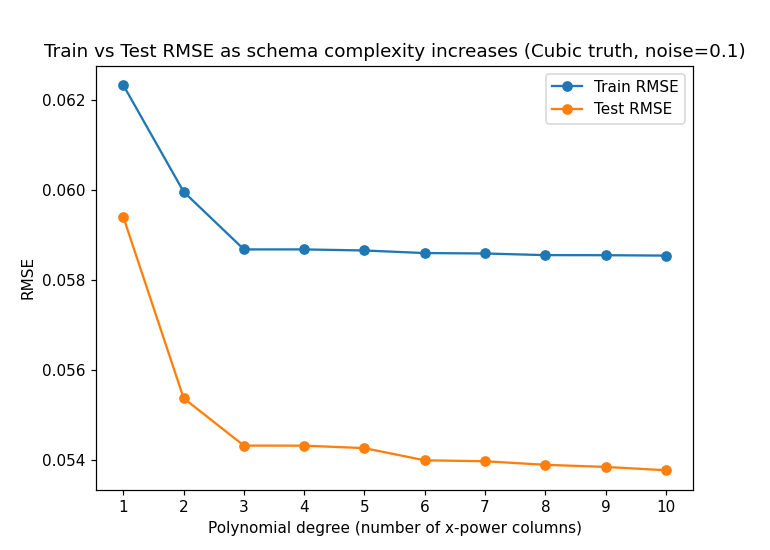

In [ ]:
true_f_cubic = lambda x: 0.5*x**3 - x**2 + x
noise_q7 = 0.1
extra_functions_10 = [lambda x, p=p: x**p for p in range(2, 11)]

df_full_q7 = generate_noisy_dataset(functions=extra_functions_10, true_function=true_f_cubic,
                                     x_range=(0.0,1.0), n_samples=1000, noise_level=noise_q7, random_state=42)
train_full_q7, test_full_q7 = split_dataset(df_full_q7, test_size=0.2, random_state=42)

degrees = list(range(1, 11))
train_rmses, test_rmses = [], []
for d in degrees:
    cols = ['x'] + [f'f_{i}' for i in range(1, d)] + ['y']
    train_sub = train_full_q7[cols]
    test_sub = test_full_q7[cols]
    beta = fit(train_sub)
    rmse_train = evaluate_model(predict(train_sub, beta), train_sub['y'].values)
    rmse_test = evaluate_model(predict(test_sub, beta), test_sub['y'].values)
    train_rmses.append(rmse_train)
    test_rmses.append(rmse_test)
    print(f"degree={d:2d}  train_rmse={rmse_train:.5f}  test_rmse={rmse_test:.5f}")

plt.figure(figsize=(7,5))
plt.plot(degrees, train_rmses, marker='o', label='Train RMSE')
plt.plot(degrees, test_rmses, marker='o', label='Test RMSE')
plt.xlabel('Polynomial degree (number of x-power columns)')
plt.ylabel('RMSE')
plt.title('Train vs Test RMSE as schema complexity increases')
plt.legend()
plt.xticks(degrees)
plt.show()

### Question 9

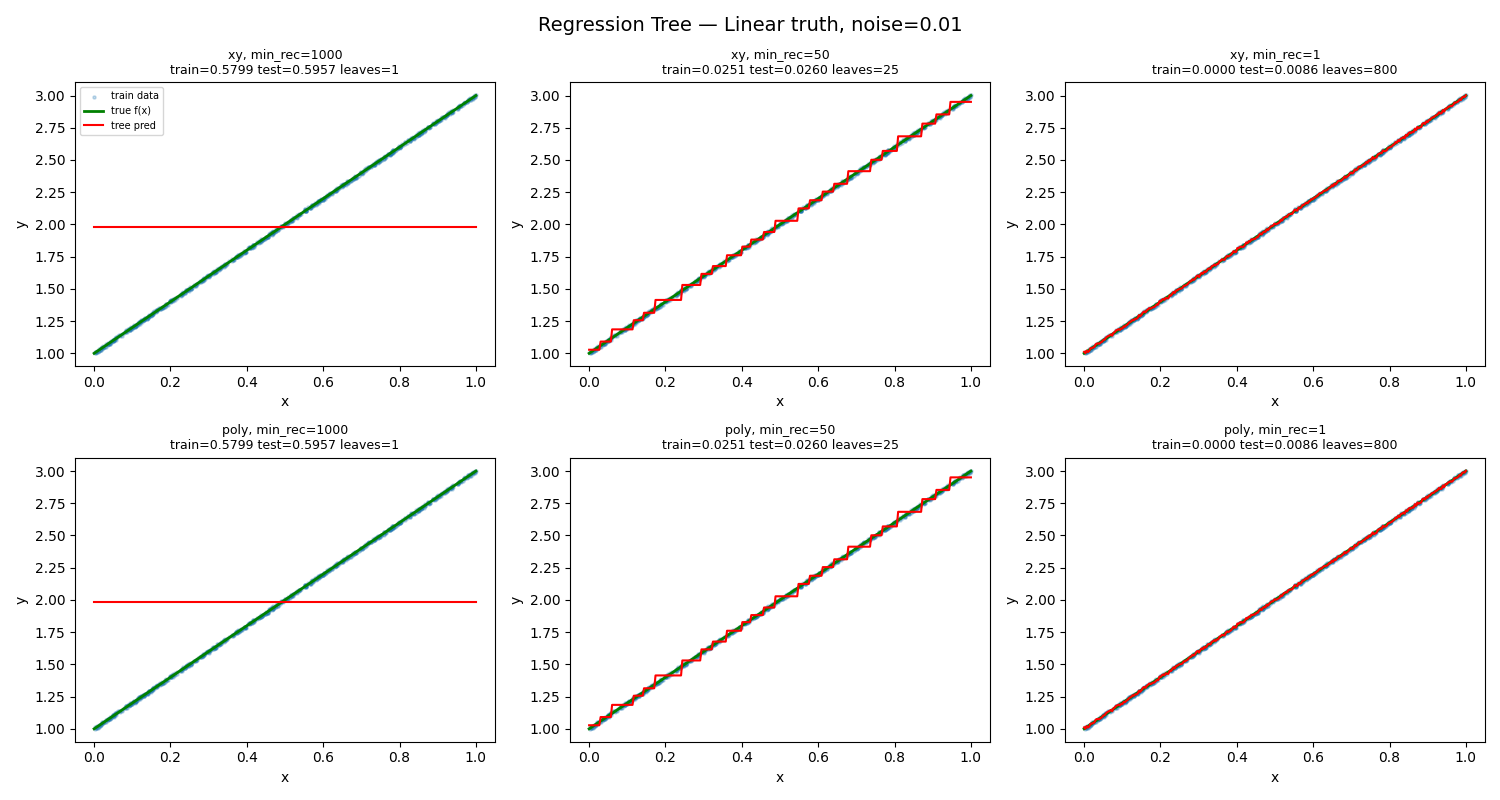

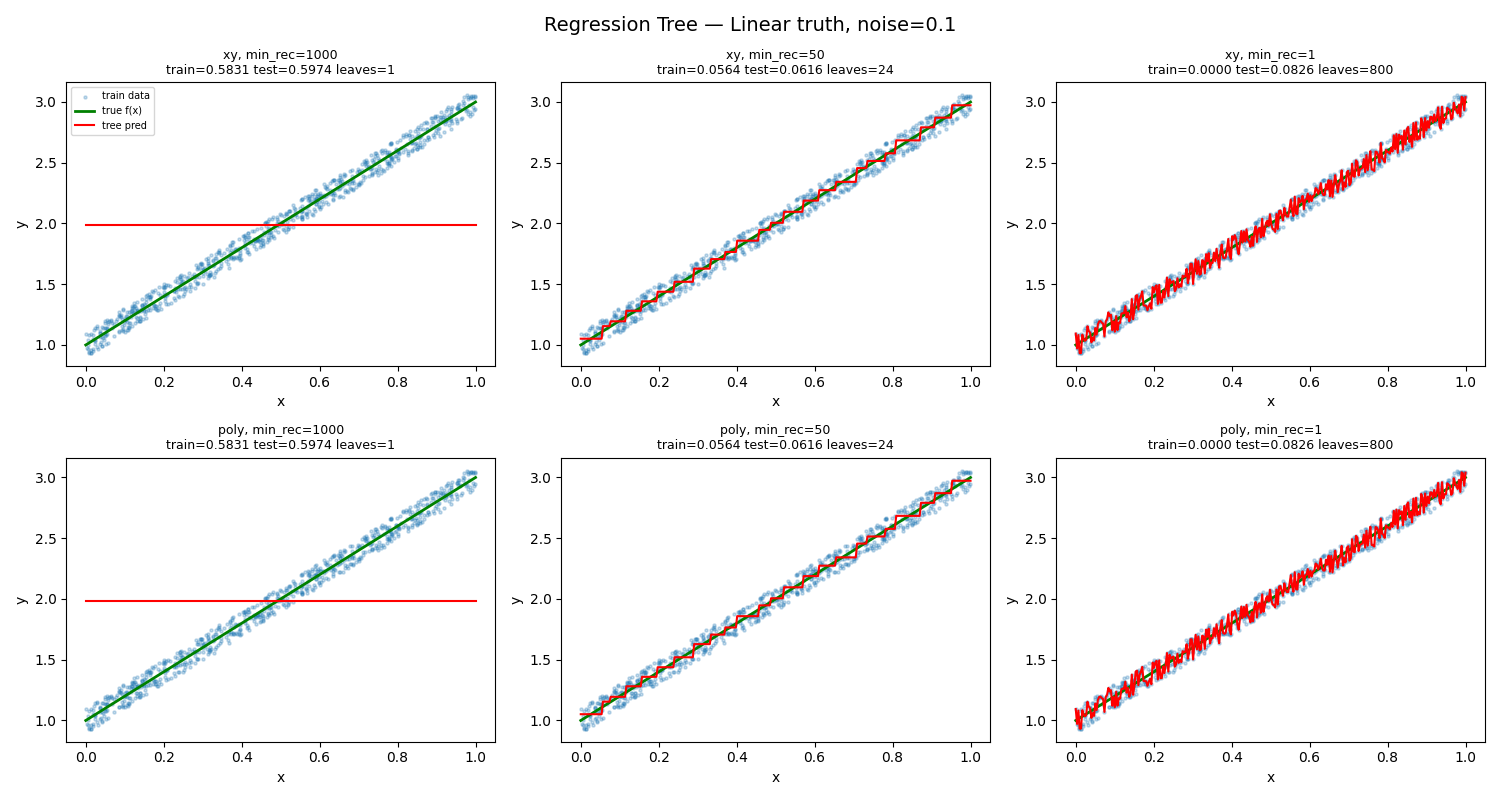

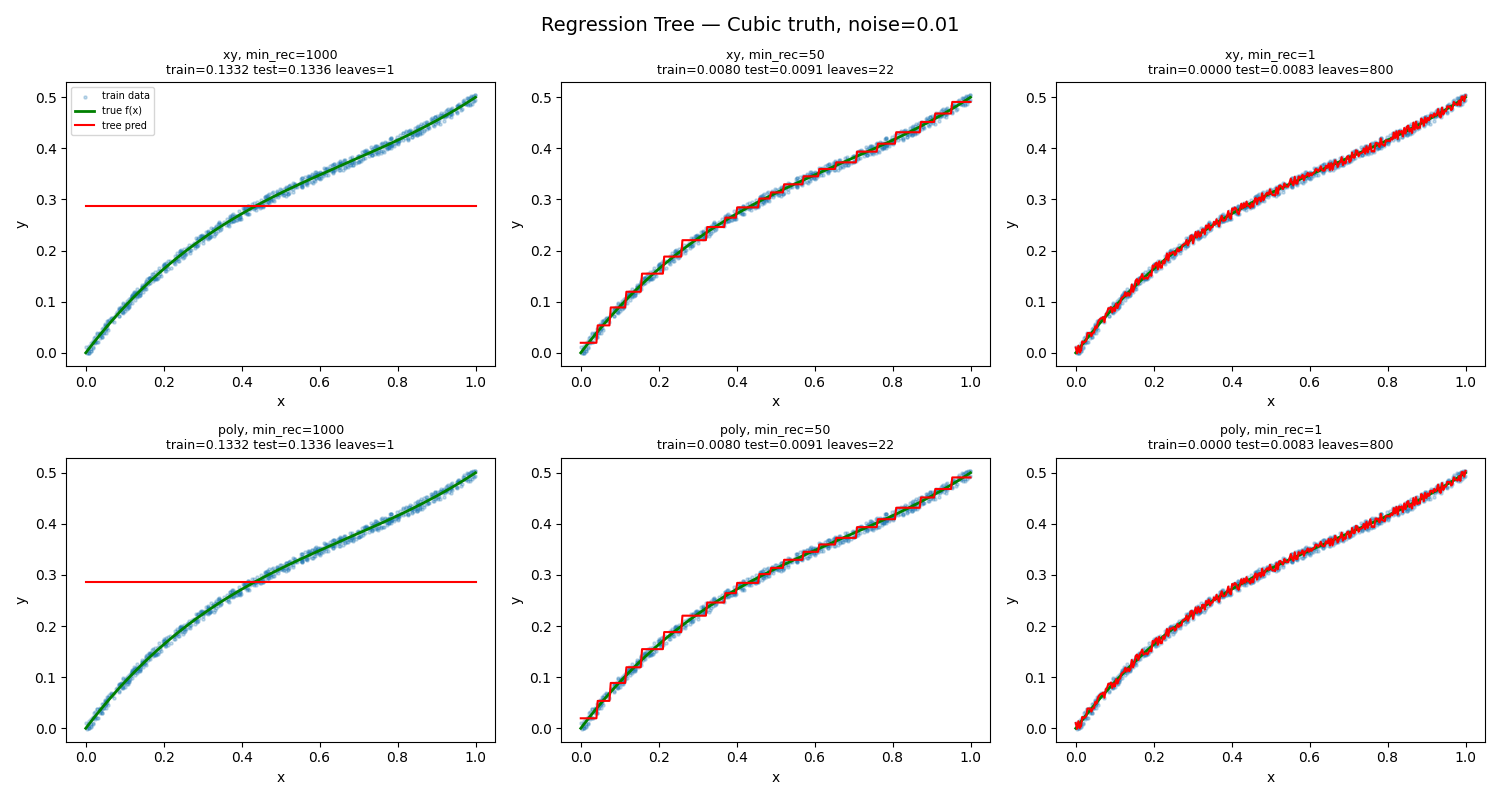

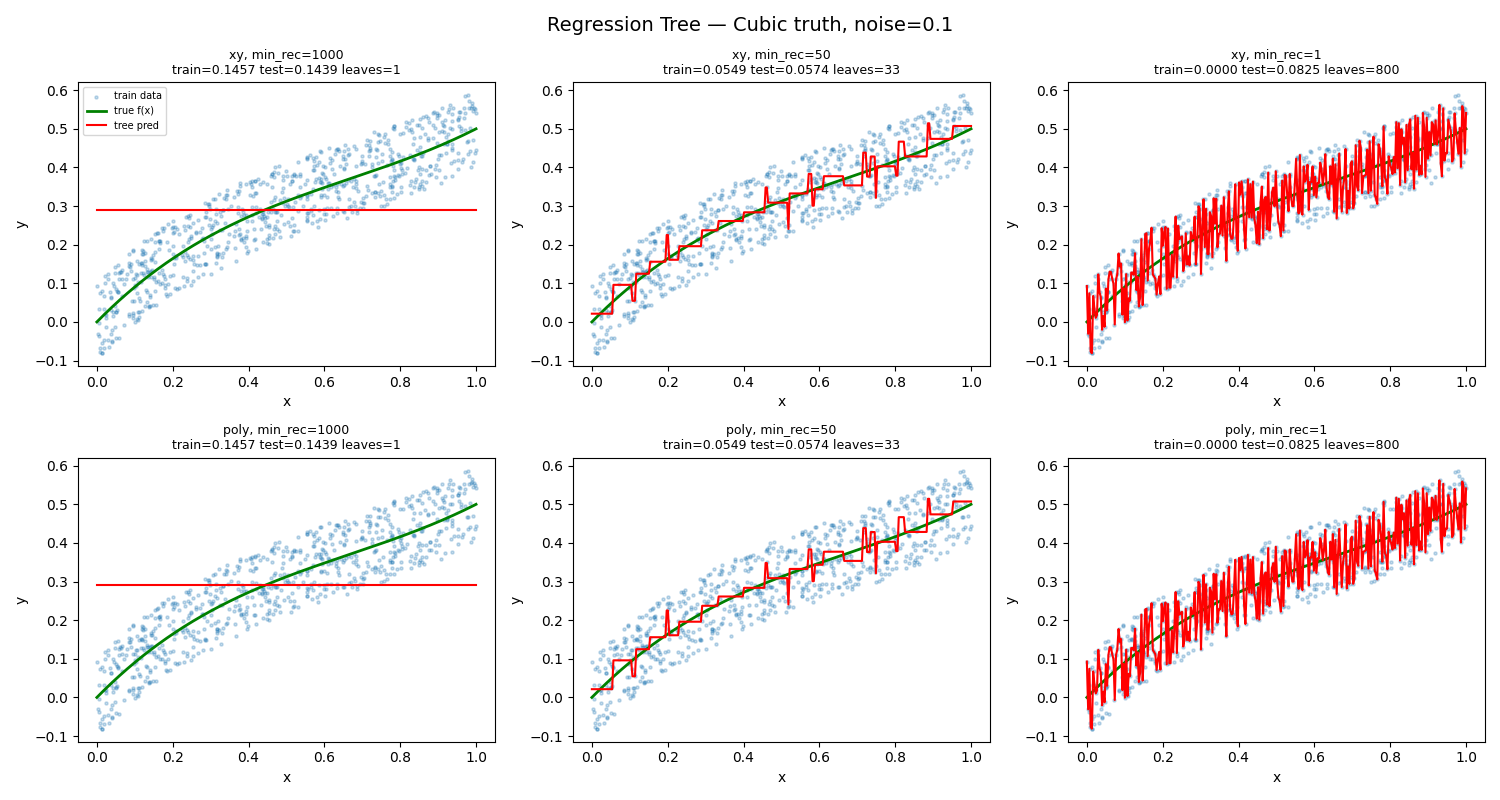

In [ ]:
def count_nodes_leaves(node):
    if node['leaf']:
        return 1, 1
    ln, ll = count_nodes_leaves(node['left'])
    rn, rl = count_nodes_leaves(node['right'])
    return 1 + ln + rn, ll + rl

min_records_list = [1000, 50, 1]
tree_results = {}

for func_name, true_f in true_functions.items():
    for noise in noise_levels:
        df_full = generate_noisy_dataset(functions=extra_functions, true_function=true_f,
                                          x_range=(0.0,1.0), n_samples=1000, noise_level=noise, random_state=42)
        train_full, test_full = split_dataset(df_full, test_size=0.2, random_state=42)

        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        fig.suptitle(f'Regression Tree -- {func_name} truth, noise={noise}', fontsize=14)

        for row_idx, schema_name, cols in [(0, 'xy', ['x','y']), (1, 'poly', ['x','f_1','f_2','y'])]:
            train_sub = train_full[cols]
            test_sub = test_full[cols]

            for col_idx, min_rec in enumerate(min_records_list):
                tree = RegressionTree()
                tree.fit(train_sub, min_records=min_rec)

                input_cols = [c for c in cols if c != 'y']
                pred_train = tree.predict(train_sub[input_cols])
                pred_test = tree.predict(test_sub[input_cols])
                rmse_train = evaluate_model(pred_train, train_sub['y'].values)
                rmse_test = evaluate_model(pred_test, test_sub['y'].values)
                n_nodes, n_leaves = count_nodes_leaves(tree.root)
                tree_results[(func_name, noise, schema_name, min_rec)] = {
                    'rmse_train': rmse_train, 'rmse_test': rmse_test, 'n_nodes': n_nodes, 'n_leaves': n_leaves
                }

                ax = axes[row_idx, col_idx]
                ax.scatter(train_sub['x'], train_sub['y'], s=5, alpha=0.25, label='train data')
                ax.plot(x_grid, true_f(x_grid), color='green', linewidth=2, label='true f(x)')
                grid_df = pd.DataFrame({'x': x_grid}) if schema_name=='xy' else pd.DataFrame({'x': x_grid, 'f_1': x_grid**2, 'f_2': x_grid**3})
                ax.plot(x_grid, tree.predict(grid_df), color='red', linewidth=1.5, label='tree pred')
                ax.set_title(f'{schema_name}, min_rec={min_rec}\ntrain={rmse_train:.4f} test={rmse_test:.4f} leaves={n_leaves}', fontsize=9)
                ax.set_xlabel('x'); ax.set_ylabel('y')
                if row_idx==0 and col_idx==0:
                    ax.legend(fontsize=7)
        fig.tight_layout()
        plt.show()


In [ ]:
for key, val in tree_results.items():
    print(key, '->', {k:(round(v,4) if isinstance(v,float) else v) for k,v in val.items()})

('Linear', 0.01, 'xy', 1000) -> {'rmse_train': 0.5799, 'rmse_test': 0.5957, 'n_nodes': 1, 'n_leaves': 1}
('Linear', 0.01, 'xy', 50) -> {'rmse_train': 0.0251, 'rmse_test': 0.026, 'n_nodes': 49, 'n_leaves': 25}
('Linear', 0.01, 'xy', 1) -> {'rmse_train': 0.0, 'rmse_test': 0.0086, 'n_nodes': 1599, 'n_leaves': 800}
('Linear', 0.01, 'poly', 1000) -> {'rmse_train': 0.5799, 'rmse_test': 0.5957, 'n_nodes': 1, 'n_leaves': 1}
('Linear', 0.01, 'poly', 50) -> {'rmse_train': 0.0251, 'rmse_test': 0.026, 'n_nodes': 49, 'n_leaves': 25}
('Linear', 0.01, 'poly', 1) -> {'rmse_train': 0.0, 'rmse_test': 0.0086, 'n_nodes': 1599, 'n_leaves': 800}
('Linear', 0.1, 'xy', 1000) -> {'rmse_train': 0.5831, 'rmse_test': 0.5974, 'n_nodes': 1, 'n_leaves': 1}
('Linear', 0.1, 'xy', 50) -> {'rmse_train': 0.0564, 'rmse_test': 0.0616, 'n_nodes': 47, 'n_leaves': 24}
('Linear', 0.1, 'xy', 1) -> {'rmse_train': 0.0, 'rmse_test': 0.0826, 'n_nodes': 1599, 'n_leaves': 800}
('Linear', 0.1, 'poly', 1000) -> {'rmse_train': 0.5831, '

### Question 10

In [ ]:
print(f"{'Func':8s} {'Noise':6s} {'Schema':6s} {'LinearRMSE':>11s} {'Tree(1000)':>11s} {'Tree(50)':>10s} {'Tree(1)':>9s}")
for func_name, true_f in true_functions.items():
    for noise in noise_levels:
        df_full = generate_noisy_dataset(functions=extra_functions, true_function=true_f,
                                          x_range=(0,1), n_samples=1000, noise_level=noise, random_state=42)
        train_full, test_full = split_dataset(df_full, test_size=0.2, random_state=42)
        for schema_name, cols in [('xy', ['x','y']), ('poly', ['x','f_1','f_2','y'])]:
            train_sub = train_full[cols]; test_sub = test_full[cols]
            beta = fit(train_sub)
            lin_rmse = evaluate_model(predict(test_sub, beta), test_sub['y'].values)
            t1000 = tree_results[(func_name, noise, schema_name, 1000)]['rmse_test']
            t50 = tree_results[(func_name, noise, schema_name, 50)]['rmse_test']
            t1 = tree_results[(func_name, noise, schema_name, 1)]['rmse_test']
            print(f"{func_name:8s} {noise:<6} {schema_name:6s} {lin_rmse:11.4f} {t1000:11.4f} {t50:10.4f} {t1:9.4f}")

Func     Noise  Schema  LinearRMSE  Tree(1000)   Tree(50)   Tree(1)
Linear   0.01   xy          0.0054      0.5957     0.0260    0.0086
Linear   0.01   poly        0.0054      0.5957     0.0260    0.0086
Linear   0.1    xy          0.0542      0.5974     0.0616    0.0826
Linear   0.1    poly        0.0543      0.5974     0.0616    0.0826
Cubic    0.01   xy          0.0215      0.1336     0.0091    0.0083
Cubic    0.01   poly        0.0054      0.1336     0.0091    0.0083
Cubic    0.1    xy          0.0594      0.1439     0.0574    0.0825
Cubic    0.1    poly        0.0543      0.1439     0.0574    0.0825


### Question 11

min_records=  2  train_rmse=0.0000  test_rmse=0.1591
min_records=  4  train_rmse=0.0586  test_rmse=0.1455
min_records=  8  train_rmse=0.0822  test_rmse=0.1482
min_records= 16  train_rmse=0.1161  test_rmse=0.1528
min_records= 32  train_rmse=0.1283  test_rmse=0.1494
min_records= 64  train_rmse=0.1718  test_rmse=0.1714
min_records=128  train_rmse=0.3064  test_rmse=0.3445
min_records=256  train_rmse=0.7574  test_rmse=0.6717


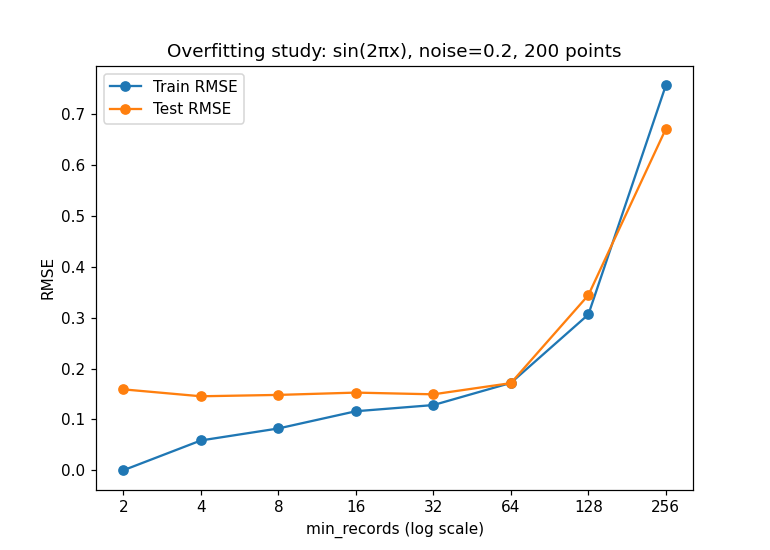

In [ ]:
true_f_sin = lambda x: np.sin(2*np.pi*x)
df_sin = generate_noisy_dataset(functions=[], true_function=true_f_sin, x_range=(0.0,1.0),
                                 n_samples=200, noise_level=0.2, random_state=42)
train_sin, test_sin = split_dataset(df_sin, test_size=0.2, random_state=42)

min_records_list_q11 = [2, 4, 8, 16, 32, 64, 128, 256]
train_rmses_q11, test_rmses_q11 = [], []
for mr in min_records_list_q11:
    tree = RegressionTree()
    tree.fit(train_sin, min_records=mr)
    rmse_train = evaluate_model(tree.predict(train_sin[['x']]), train_sin['y'].values)
    rmse_test = evaluate_model(tree.predict(test_sin[['x']]), test_sin['y'].values)
    train_rmses_q11.append(rmse_train)
    test_rmses_q11.append(rmse_test)
    print(f"min_records={mr:3d}  train_rmse={rmse_train:.4f}  test_rmse={rmse_test:.4f}")

plt.figure(figsize=(7,5))
plt.plot(min_records_list_q11, train_rmses_q11, marker='o', label='Train RMSE')
plt.plot(min_records_list_q11, test_rmses_q11, marker='o', label='Test RMSE')
plt.xscale('log', base=2)
plt.xlabel('min_records (log scale)')
plt.ylabel('RMSE')
plt.title('Overfitting study: sin(2πx), noise=0.2, 200 points')
plt.legend()
plt.xticks(min_records_list_q11, min_records_list_q11)
plt.show()